# Полносвязные нейронные сети
В этом упражнении вы реализуете полносвязные нейронные сети, используя модульный подход. Для каждого слоя нужно написать две функции: `forward` и `backward`. Функция `forward` принимает входные данные, веса и другие параметры и возвращает выход, а также объект `cache`, в котором хранятся данные, нужные для обратного прохода, например так:

```python
def layer_forward(x, w):
  """ Принимает входы x и веса w """
  # Какие-то вычисления ...
  z = # ... какое-то промежуточное значение
  # Ещё какие-то вычисления ...
  out = # выход

  cache = (x, w, z, out) # Значения, нужные для вычисления градиентов

  return out, cache
```

Функция обратного прохода получает градиент, пришедший сверху (upstream), и объект `cache` и возвращает градиенты по входам и по весам, например так:

```python
def layer_backward(dout, cache):
  """
  Принимает dout (производную функции потерь по выходам) и cache
  и вычисляет производные по входам.
  """
  # Распаковываем значения из cache
  x, w, z, out = cache

  # По значениям из cache вычисляем производные
  dx = # Производная функции потерь по x
  dw = # Производная функции потерь по w

  return dx, dw
```

Реализовав таким образом набор слоёв, вы сможете легко комбинировать их и строить классификаторы с разной архитектурой.

In [1]:
# Настройка окружения (запустите эту ячейку первой).
# Откройте ноутбук из папки python/ задания, например: uv run jupyter lab
# При первом запуске скачается CIFAR-10 (~170 МБ): с сервера курса, а если он
# недоступен, с официального сайта. Источник можно задать явно переменной
# окружения DLCV_DATASET_SOURCE=racoon или official перед запуском Jupyter.
import os
import sys

if not os.path.isdir('dlcv'):
    raise FileNotFoundError(
        'В текущей папке нет пакета dlcv. Откройте ноутбук из папки python/ задания.')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from dlcv.data_utils import ensure_cifar10
ensure_cifar10()
print('Рабочая папка:', os.getcwd())

Рабочая папка: c:\Users\Artemiy\Desktop\MAGA\DL\dl-assignment1-template\python


In [2]:
# Как обычно, немного подготовки
import time
import numpy as np
import matplotlib.pyplot as plt
from dlcv.classifiers.fc_net import *
from dlcv.data_utils import get_CIFAR10_data
from dlcv.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from dlcv.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # размер графиков по умолчанию
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# автоматическая перезагрузка внешних модулей
# см. http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ Возвращает относительную ошибку. """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [3]:
# Загружаем (предобработанные) данные CIFAR-10.

data = get_CIFAR10_data()
for k, v in list(data.items()):
  print('%s: ' % k, v.shape)

X_train:  (49000, 3, 32, 32)
y_train:  (49000,)
X_val:  (1000, 3, 32, 32)
y_val:  (1000,)
X_test:  (1000, 3, 32, 32)
y_test:  (1000,)


# Аффинный слой: прямой проход
Откройте файл `dlcv/layers.py` и реализуйте функцию `affine_forward`.

Когда закончите, проверьте свою реализацию, запустив следующую ячейку:

In [4]:
# Проверка функции affine_forward

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

# Сравниваем ваш выход с эталонным. Ошибка должна быть порядка e-9 или меньше.
print('Проверка функции affine_forward:')
print('разница: ', rel_error(out, correct_out))

Проверка функции affine_forward:
разница:  9.769849468192957e-10


# Аффинный слой: обратный проход
Теперь реализуйте функцию `affine_backward` и проверьте реализацию с помощью численной проверки градиента (gradient check).

In [5]:
# Проверка функции affine_backward
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# Ошибка должна быть порядка e-10 или меньше
print('Проверка функции affine_backward:')
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dw: ', rel_error(dw_num, dw))
print('ошибка db: ', rel_error(db_num, db))

Проверка функции affine_backward:
ошибка dx:  5.399100368651805e-11
ошибка dw:  9.904211865398145e-11
ошибка db:  2.4122867568119087e-11


# Активация ReLU: прямой проход
Реализуйте прямой проход для функции активации ReLU в функции `relu_forward` и проверьте реализацию с помощью следующей ячейки:

In [6]:
# Проверка функции relu_forward

x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Сравниваем ваш выход с эталонным. Ошибка должна быть порядка e-8
print('Проверка функции relu_forward:')
print('разница: ', rel_error(out, correct_out))

Проверка функции relu_forward:
разница:  4.999999798022158e-08


# Активация ReLU: обратный проход
Теперь реализуйте обратный проход для функции активации ReLU в функции `relu_backward` и проверьте реализацию с помощью численной проверки градиента:

In [7]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# Ошибка должна быть порядка e-12
print('Проверка функции relu_backward:')
print('ошибка dx: ', rel_error(dx_num, dx))

Проверка функции relu_backward:
ошибка dx:  3.2756349136310288e-12


## Вопрос 1

В этой работе требуется реализовать только ReLU, однако в нейронных сетях можно использовать и многие другие функции активации, у каждой из которых есть свои плюсы и минусы. В частности, с функциями активации часто возникает такая проблема: при обратном распространении ошибки через них проходит нулевой (или близкий к нулю) градиент. У каких из перечисленных ниже функций активации есть эта проблема? Если рассматривать эти функции в одномерном случае, при каких входных значениях возникает такое поведение?
1. Сигмоида (sigmoid)
2. ReLU
3. Leaky ReLU

**Ваш ответ:** 

У sigmoid градиент становится близким к нулю при больших по модулю входах, когда функция насыщается около 0 или 1. У ReLU градиент равен нулю при неположительных входах. У Leaky ReLU градиент обычно не обнуляется: для отрицательных входов сохраняется небольшой ненулевой наклон, а для положительных он равен 1.

# Составные слои («сэндвичи»)
В нейронных сетях часто встречаются типовые последовательности слоёв. Например, за аффинным слоем обычно следует нелинейность ReLU. Чтобы с такими типовыми связками было удобно работать, в файле `dlcv/layer_utils.py` определено несколько вспомогательных составных слоёв.

Пока просто посмотрите на функции `affine_relu_forward` и `affine_relu_backward` и запустите следующую ячейку, чтобы численно проверить градиент обратного прохода:

In [8]:
from dlcv.layer_utils import affine_relu_forward, affine_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

# Относительная ошибка должна быть порядка e-10 или меньше
print('Проверка affine_relu_forward и affine_relu_backward:')
print('ошибка dx: ', rel_error(dx_num, dx))
print('ошибка dw: ', rel_error(dw_num, dw))
print('ошибка db: ', rel_error(db_num, db))

Проверка affine_relu_forward и affine_relu_backward:
ошибка dx:  2.299579177309368e-11
ошибка dw:  8.162011105764925e-11
ошибка db:  7.826724021458994e-12


# Слои функции потерь: softmax
Теперь реализуйте вычисление функции потерь softmax и её градиента в функции `softmax_loss` в файле `dlcv/layers.py`. Реализация должна быть похожа на то, что вы написали в `dlcv/classifiers/softmax.py`.

Чтобы убедиться в правильности реализации, запустите следующую ячейку:

In [9]:
np.random.seed(231)
num_classes, num_inputs = 10, 50
x = 0.001 * np.random.randn(num_inputs, num_classes)
y = np.random.randint(num_classes, size=num_inputs)


dx_num = eval_numerical_gradient(lambda x: softmax_loss(x, y)[0], x, verbose=False)
loss, dx = softmax_loss(x, y)

# Проверка функции softmax_loss. Значение потерь должно быть близко к 2.3,
# а ошибка dx — порядка e-8
print('\nПроверка softmax_loss:')
print('потери: ', loss)
print('ошибка dx: ', rel_error(dx_num, dx))


Проверка softmax_loss:
потери:  2.3025458445007376
ошибка dx:  8.234144091578429e-09


# Двухслойная сеть
Откройте файл `dlcv/classifiers/fc_net.py` и допишите реализацию класса `TwoLayerNet`. Внимательно прочитайте код, чтобы разобраться в его интерфейсе (API). Проверить свою реализацию можно, запустив ячейку ниже.

In [12]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Проверка инициализации ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'Похоже, веса первого слоя инициализированы неправильно'
assert np.all(b1 == 0), 'Похоже, смещения первого слоя инициализированы неправильно'
assert W2_std < std / 10, 'Похоже, веса второго слоя инициализированы неправильно'
assert np.all(b2 == 0), 'Похоже, смещения второго слоя инициализированы неправильно'

print('Проверка прямого прохода в режиме тестирования ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Ошибка в прямом проходе в режиме тестирования'

print('Проверка функции потерь при обучении (без регуляризации)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Ошибка в значении функции потерь при обучении'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Ошибка в значении функции потерь с регуляризацией'

# Ошибки должны быть порядка e-7 или меньше
for reg in [0.0, 0.7]:
  print('Численная проверка градиента при reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s — относительная ошибка: %.2e' % (name, rel_error(grad_num, grads[name])))

Проверка инициализации ... 
Проверка прямого прохода в режиме тестирования ... 
Проверка функции потерь при обучении (без регуляризации)
Численная проверка градиента при reg =  0.0
W1 — относительная ошибка: 1.83e-08
W2 — относительная ошибка: 3.20e-10
b1 — относительная ошибка: 9.83e-09
b2 — относительная ошибка: 4.33e-10
Численная проверка градиента при reg =  0.7
W1 — относительная ошибка: 2.53e-07
W2 — относительная ошибка: 2.85e-08
b1 — относительная ошибка: 1.56e-08
b2 — относительная ошибка: 9.09e-10


# Обучение с помощью `Solver`
Откройте файл `dlcv/solver.py` и прочитайте его, чтобы познакомиться с интерфейсом (API). После этого с помощью объекта `Solver` обучите `TwoLayerNet` так, чтобы точность (accuracy, доля правильных ответов) на валидационной выборке составила около `36%`.

In [17]:
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
model = TwoLayerNet(input_size, hidden_size, num_classes)
solver = None

##############################################################################
# TODO: С помощью объекта Solver обучите TwoLayerNet так, чтобы              #
# точность на валидационной выборке составила около 36%.                     #
##############################################################################
solver = Solver(
    model,
    data,
    update_rule="sgd",
    optim_config={
        "learning_rate": 1e-4,
    },
    lr_decay=0.95,
    num_epochs=6,
    batch_size=100,
    print_every=100
)

solver.train()
##############################################################################
#                             КОНЕЦ ВАШЕГО КОДА                              #
##############################################################################

(Итерация 1 / 2940) потери: 2.306528
(Эпоха 0 / 6) точность на обучении: 0.088000; на валидации: 0.109000
(Итерация 101 / 2940) потери: 2.261962
(Итерация 201 / 2940) потери: 2.148142
(Итерация 301 / 2940) потери: 2.024372
(Итерация 401 / 2940) потери: 2.050939
(Эпоха 1 / 6) точность на обучении: 0.289000; на валидации: 0.292000
(Итерация 501 / 2940) потери: 1.973706
(Итерация 601 / 2940) потери: 1.945867
(Итерация 701 / 2940) потери: 1.916830
(Итерация 801 / 2940) потери: 1.959954
(Итерация 901 / 2940) потери: 1.882401
(Эпоха 2 / 6) точность на обучении: 0.366000; на валидации: 0.345000
(Итерация 1001 / 2940) потери: 1.771793
(Итерация 1101 / 2940) потери: 1.904664
(Итерация 1201 / 2940) потери: 1.747580
(Итерация 1301 / 2940) потери: 1.711845
(Итерация 1401 / 2940) потери: 1.789076
(Эпоха 3 / 6) точность на обучении: 0.370000; на валидации: 0.386000
(Итерация 1501 / 2940) потери: 1.645966
(Итерация 1601 / 2940) потери: 1.710535
(Итерация 1701 / 2940) потери: 1.612285
(Итерация 1801 /

# Отладка обучения
Если обучать сеть с небольшой скоростью обучения всего несколько эпох (например, `learning_rate=1e-4`, 5 эпох), точность на валидационной выборке получится около 0.36. Это не очень хороший результат.

Один из способов понять, что идёт не так, — построить графики функции потерь и точности на обучающей и валидационной выборках в процессе оптимизации.

Другой способ — визуализировать веса, которые выучил первый слой сети. У большинства нейронных сетей, обученных на изображениях, веса первого слоя при визуализации обычно имеют заметную структуру.

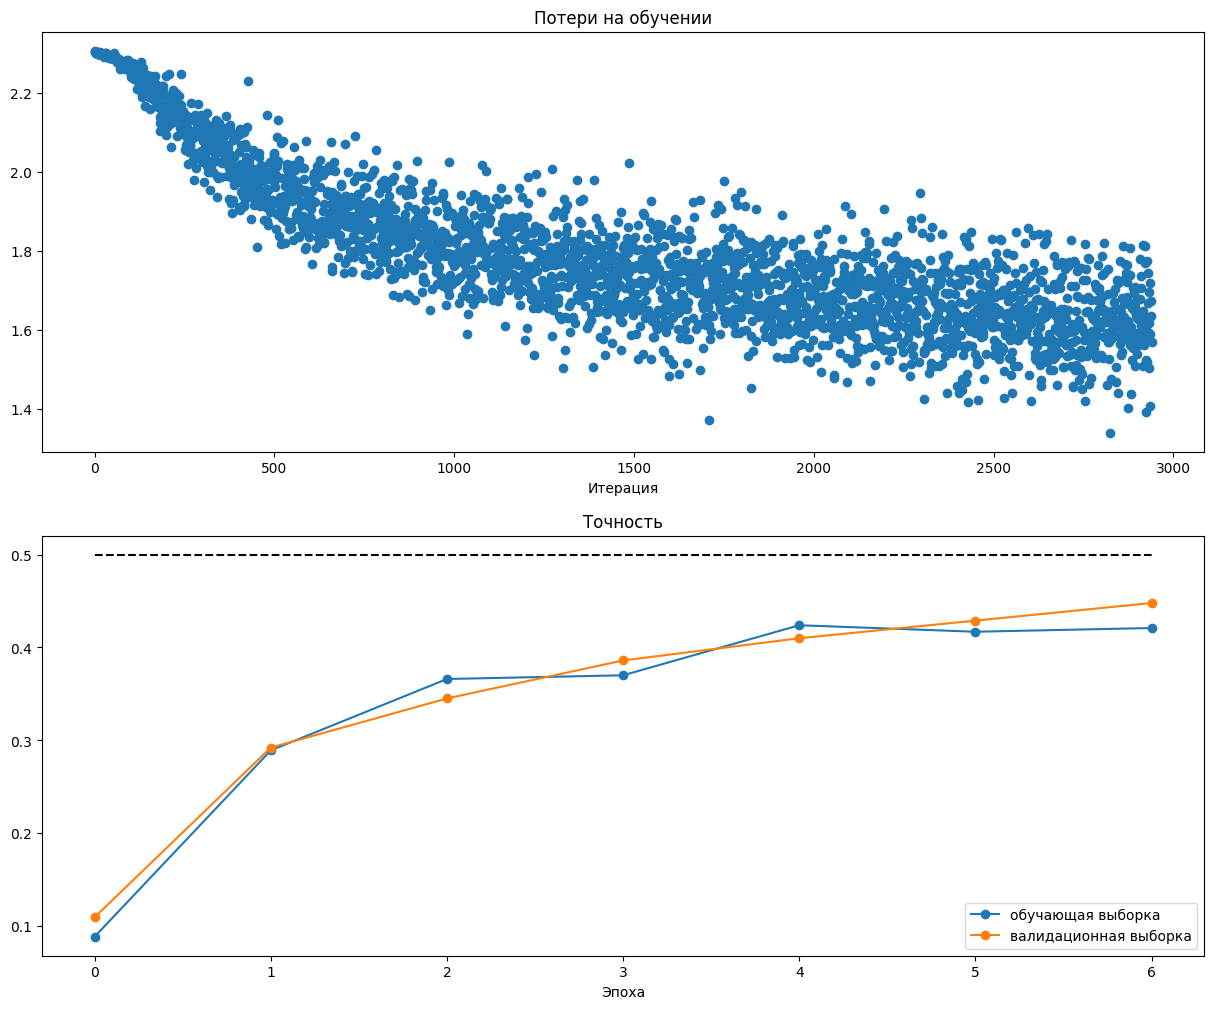

In [18]:
# Запустите эту ячейку, чтобы построить графики функции потерь на обучающей
# выборке и точности на обучающей и валидационной выборках

plt.subplot(2, 1, 1)
plt.title('Потери на обучении')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Итерация')

plt.subplot(2, 1, 2)
plt.title('Точность')
plt.plot(solver.train_acc_history, '-o', label='обучающая выборка')
plt.plot(solver.val_acc_history, '-o', label='валидационная выборка')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Эпоха')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

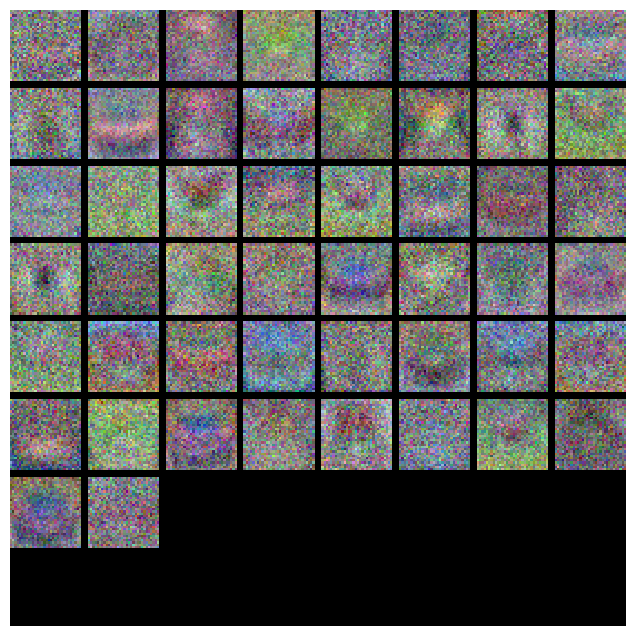

In [19]:
from dlcv.vis_utils import visualize_grid

# Визуализация весов сети

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(3, 32, 32, -1).transpose(3, 1, 2, 0)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.gca().axis('off')
    plt.show()

show_net_weights(model)

# Подбор гиперпараметров

**Что не так?** На графиках выше видно, что функция потерь убывает более-менее линейно, а это говорит о том, что скорость обучения (learning rate), возможно, слишком мала. Кроме того, между точностью на обучающей и валидационной выборках нет разрыва: по-видимому, у использованной модели низкая ёмкость и её размер стоит увеличить. С другой стороны, у очень большой модели следует ожидать более сильного переобучения, которое проявится как очень большой разрыв между точностью на обучающей и валидационной выборках.

**Подбор.** Подбор гиперпараметров и развитие интуиции о том, как они влияют на итоговое качество, — значительная часть работы с нейронными сетями, поэтому здесь важно как следует попрактиковаться. Ниже поэкспериментируйте с разными значениями гиперпараметров, в том числе с размером скрытого слоя, скоростью обучения, числом эпох обучения и коэффициентом регуляризации. Можно также настроить затухание скорости обучения, но хорошего качества вполне можно добиться и со значением по умолчанию.

**Ориентировочные результаты.** Постарайтесь добиться точности классификации выше 48% на валидационной выборке. Хорошо настроенная сеть достигает на валидационной выборке более 52%.

**Эксперимент.** Ваша цель в этом упражнении — получить на CIFAR-10 как можно более высокий результат (ориентир — 52%) с помощью полносвязной нейронной сети. Можете свободно применять собственные приёмы (например, PCA для снижения размерности, dropout, доработку `Solver` и т. п.).

hidden=100, scale=0.001, lr=0.001, reg=0.1: val=0.5260
hidden=200, scale=0.001, lr=0.001, reg=0.1: val=0.5410
hidden=200, scale=0.001, lr=0.001, reg=0.5: val=0.5540
hidden=200, scale=0.002, lr=0.001, reg=0.5: val=0.5610

Лучшая конфигурация: (200, 0.002, 0.001, 0.5)
Лучшая валидационная точность: 0.561


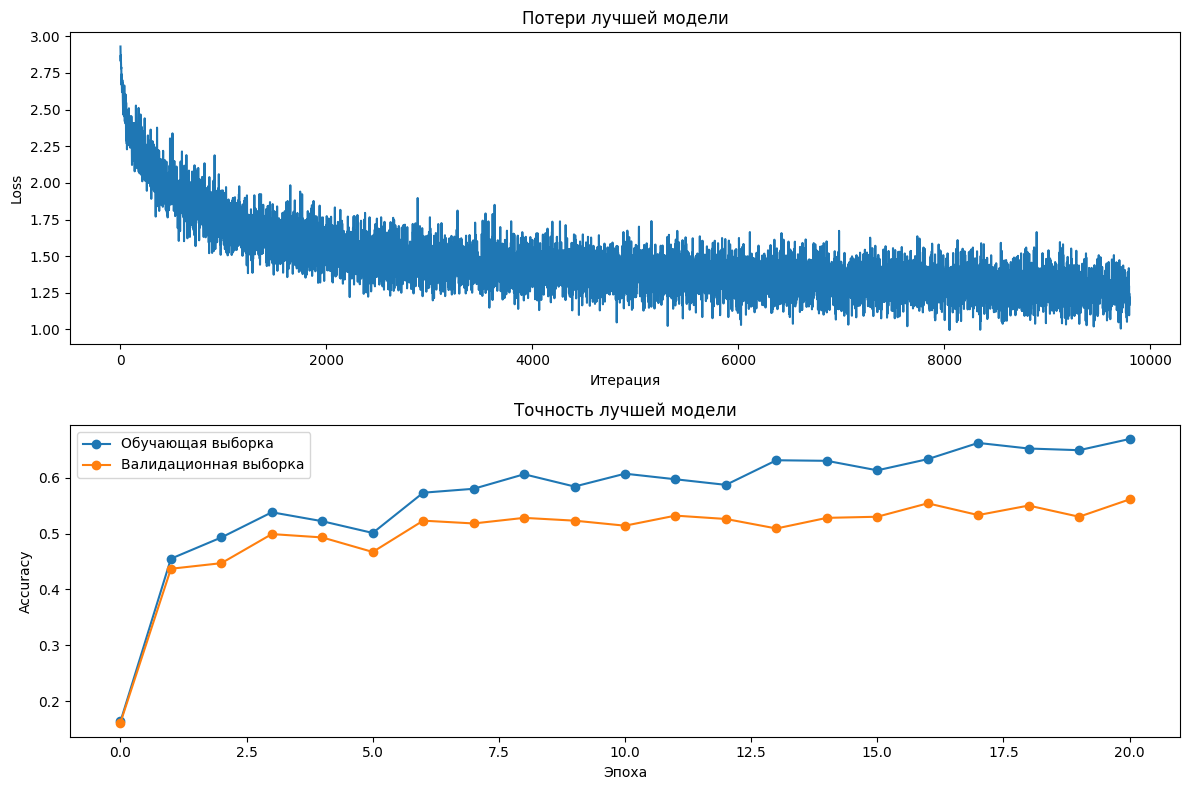

In [21]:
best_model = None



#################################################################################
# TODO: Подберите гиперпараметры с помощью валидационной выборки.               #
# Сохраните лучшую обученную модель в best_model.                               #
#                                                                               #
# Для отладки сети могут пригодиться визуализации, подобные тем, что            #
# использовались выше; у хорошо настроенной сети они будут существенно          #
# отличаться по характеру от тех, что получены выше для плохо                   #
# настроенной сети.                                                             #
#                                                                               #
# Подбирать гиперпараметры вручную бывает интересно, но, возможно, вам          #
# будет удобнее написать код, который автоматически перебирает возможные        #
# комбинации гиперпараметров, как в предыдущих упражнениях.                     #
#################################################################################
best_model = None
best_solver = None
best_config = None
best_val = -1

configurations = [
    # hidden_size, weight_scale, learning_rate, reg
    (100, 1e-3, 1e-3, 0.1),
    (200, 1e-3, 1e-3, 0.1),
    (200, 1e-3, 1e-3, 0.5),
    (200, 2e-3, 1e-3, 0.5),
]

for hidden_size, weight_scale, learning_rate, reg in configurations:
    model = TwoLayerNet(
        input_dim=32 * 32 * 3,
        hidden_dim=hidden_size,
        num_classes=10,
        weight_scale=weight_scale,
        reg=reg
    )

    solver = Solver(
        model,
        data,
        update_rule="sgd",
        optim_config={"learning_rate": learning_rate},
        lr_decay=0.95,
        num_epochs=20,
        batch_size=100,
        print_every=200,
        verbose=False
    )

    solver.train()

    print(
        f"hidden={hidden_size}, scale={weight_scale}, "
        f"lr={learning_rate}, reg={reg}: "
        f"val={solver.best_val_acc:.4f}"
    )

    if solver.best_val_acc > best_val:
        best_val = solver.best_val_acc
        best_model = model
        best_solver = solver
        best_config = (
            hidden_size,
            weight_scale,
            learning_rate,
            reg
        )

print("\nЛучшая конфигурация:", best_config)
print("Лучшая валидационная точность:", best_val)

plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(best_solver.loss_history)
plt.title("Потери лучшей модели")
plt.xlabel("Итерация")
plt.ylabel("Loss")

plt.subplot(2, 1, 2)
plt.plot(
    best_solver.train_acc_history,
    "-o",
    label="Обучающая выборка"
)
plt.plot(
    best_solver.val_acc_history,
    "-o",
    label="Валидационная выборка"
)
plt.title("Точность лучшей модели")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()
################################################################################
#                              КОНЕЦ ВАШЕГО КОДА                               #
################################################################################

# Проверьте свою модель!
Оцените лучшую модель на валидационной и тестовой выборках. Точность и на валидационной, и на тестовой выборке должна быть выше 48%.

In [22]:
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Точность на валидационной выборке: ', (y_val_pred == data['y_val']).mean())

Точность на валидационной выборке:  0.561


In [23]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
print('Точность на тестовой выборке: ', (y_test_pred == data['y_test']).mean())

Точность на тестовой выборке:  0.541


In [24]:
# Сохраняем лучшую модель (файл появится в папке `dlcv/saved/`)
best_model.save("best_two_layer_net.npy")

best_two_layer_net.npy сохранён.


## Вопрос 2

Теперь, когда вы обучили классификатор на основе нейронной сети, вы можете заметить, что точность на тестовой выборке намного ниже, чем на обучающей. Какими способами можно уменьшить этот разрыв? Выберите все подходящие варианты.

1. Обучать на большем наборе данных.
2. Увеличить число нейронов скрытого слоя.
3. Увеличить коэффициент регуляризации.
4. Ничего из перечисленного.

**Ваш ответ:** 1,3

**Ваше объяснение:** 

Обучение на большем наборе данных помогает модели лучше обобщать результат и снижает вероятность запоминания отдельных обучающих примеров. Увеличение коэффициента регуляризации ограничивает сложность модели и также уменьшает переобучение. Увеличение числа нейронов скрытого слоя повышает емкость сети и может ещё сильнее увеличить разрыв между обучающей и тестовой точностью.